# 03 · Variantes de tokenizers sous-mot

**À retenir**
| Algorithme | Sens de construction | Critère | Utilisé par |
|---|---|---|---|
| **BPE** [1] | bas → haut (fusions) | fréquence de la paire $n(a,b)$ | GPT-2/3/4, LLaMA-3, Qwen (variantes octets) |
| **WordPiece** [2] | bas → haut | $\dfrac{n(a,b)}{n(a)\,n(b)}$ (vraisemblance) | BERT |
| **Unigram LM** [3, 4] | haut → bas (élagage) | vraisemblance $\prod p(x_i)$, segmentation par Viterbi | SentencePiece (T5, LLaMA-1/2 → BPE) |

Objectif : comparer sous **même corpus, même taille de vocabulaire**, compression, fertilité, robustesse aux caractères inconnus et vitesse.

## 1. Corpus (entraînement) et texte de test hors domaine

In [1]:
from collections import Counter
import re, math, time
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

TRAIN = ("le langage est un outil pour penser, apprendre et partager des idées. un modèle apprend des régularités en observant des exemples. "
         "l'attention causale permet à chaque position de regarder le passé. the model learns patterns from many examples. "
         "tokenization splits text into subword units and language models predict the next token. "
         "les chercheurs comparent les hypothèses avec un protocole contrôlé. ") * 25
TEST_IN = "les chercheurs comparent des modèles. the researchers compare models."   # même alphabet que l'entraînement
TEST_OOV = "Café ☕ 2024 — 雪"                                                            # caractères jamais vus
WORD = re.compile(r"\w+|[^\w\s]", re.UNICODE)
mots = Counter(WORD.findall(TRAIN))
print(f"{len(TRAIN):,} caractères d'entraînement, {len(mots)} mots distincts")

10,000 caractères d'entraînement, 57 mots distincts


## 2. Implémentations compactes (mêmes API : `entrainer(V)`, `tokeniser(texte)`)

In [2]:
PRE = re.compile(r"""'(?:s|t|re|ve|m|ll|d)| ?[^\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+""")

def _apply_merge(seq, a, b, new):
    out, i = [], 0
    while i < len(seq):
        if i + 1 < len(seq) and seq[i] == a and seq[i+1] == b: out.append(new); i += 2
        else: out.append(seq[i]); i += 1
    return out

class BPEChar:   # BPE sur caractères, pré-tokenisation par mots
    nom = "BPE (caractères)"
    def entrainer(self, V):
        w = Counter(PRE.findall(TRAIN)); seqs = {k: list(k) for k in w}
        self.base = sorted({c for k in w for c in k}); self.merges = []
        while len(self.base) + len(self.merges) < V:
            p = Counter()
            for k, s in seqs.items():
                for pair in zip(s, s[1:]): p[pair] += w[k]
            if not p: break
            (a, b), n = max(p.items(), key=lambda kv: (kv[1], kv[0]))
            if n < 2: break
            self.merges.append((a, b)); seqs = {k: _apply_merge(s, a, b, a + b) for k, s in seqs.items()}
        self.vocab = set(self.base) | {a + b for a, b in self.merges}; return self
    def tokeniser(self, t):
        out = []
        for w in PRE.findall(t):
            s = list(w)
            for a, b in self.merges: s = _apply_merge(s, a, b, a + b)
            out += [x if x in self.vocab else "<unk>" for x in s]
        return out

class BPEByte:   # BPE sur octets UTF-8 (aucun <unk>)
    nom = "BPE (octets)"
    def entrainer(self, V):
        w = Counter(PRE.findall(TRAIN)); seqs = {k: list(k.encode()) for k in w}; self.merges = []
        while 256 + len(self.merges) < V:
            p = Counter()
            for k, s in seqs.items():
                for pair in zip(s, s[1:]): p[pair] += w[k]
            if not p: break
            best, n = max(p.items(), key=lambda kv: (kv[1], kv[0]))
            if n < 2: break
            nid = 256 + len(self.merges); self.merges.append(best)
            seqs = {k: _apply_merge(s, best[0], best[1], nid) for k, s in seqs.items()}
        self.rang = {m: i for i, m in enumerate(self.merges)}; return self
    def tokeniser(self, t):
        out = []
        for w in PRE.findall(t):
            s = list(w.encode())
            while len(s) > 1:
                r, i = min((self.rang.get(p, 10**9), i) for i, p in enumerate(zip(s, s[1:])))
                if r == 10**9: break
                s[i:i+2] = [256 + r]
            out += s
        return out

class WordPiece:   # score = n(ab) / (n(a) n(b)) ; encodage glouton par plus long préfixe
    nom = "WordPiece"
    def entrainer(self, V):
        seqs = {k: [k[0]] + ["##" + c for c in k[1:]] for k in mots}; vocab = {s for q in seqs.values() for s in q}
        while len(vocab) < V:
            u, d = Counter(), Counter()
            for k, s in seqs.items():
                for x in s: u[x] += mots[k]
                for pair in zip(s, s[1:]): d[pair] += mots[k]
            if not d: break
            (a, b), _ = max(d.items(), key=lambda kv: (kv[1] / (u[kv[0][0]] * u[kv[0][1]]), kv[0]))
            new = a + b[2:]; vocab.add(new); seqs = {k: _apply_merge(s, a, b, new) for k, s in seqs.items()}
        self.vocab = vocab; return self
    def tokeniser(self, t):
        out = []
        for w in WORD.findall(t):
            i, pieces = 0, []
            while i < len(w):
                j = len(w)
                while j > i and (w[i:j] if i == 0 else "##" + w[i:j]) not in self.vocab: j -= 1
                if j == i: pieces = ["<unk>"]; break
                pieces.append(w[i:j] if i == 0 else "##" + w[i:j]); i = j
            out += pieces
        return out

class Unigram:   # EM « dur » (Viterbi) + élagage : approximation pédagogique, PAS l'EM complet de SentencePiece
    nom = "Unigram (approx.)"
    def entrainer(self, V, max_len=8, iters=6):
        c = Counter()
        for k, f in mots.items():
            for i in range(len(k)):
                for j in range(i + 1, min(len(k), i + max_len) + 1): c[k[i:j]] += f
        self.chars = {x for x in c if len(x) == 1}
        self.p = {x: n for x, n in c.items() if n >= 2 or len(x) == 1}
        while True:
            tot = sum(self.p.values()); self.lp = {x: math.log(n / tot) for x, n in self.p.items()}
            usage = Counter()
            for k, f in mots.items():
                for x in self._viterbi(k): usage[x] += f
            if len(self.p) <= V: break
            cible = max(V, int(len(self.p) * 0.8))
            garde = sorted((x for x in self.p if x not in self.chars), key=lambda x: -usage[x])[: cible - len(self.chars)]
            self.p = {x: max(usage[x], 1) for x in list(garde) + list(self.chars)}
        return self
    def _viterbi(self, w):
        best = [0.0] + [-1e18] * len(w); back = [0] * (len(w) + 1)
        for j in range(1, len(w) + 1):
            for i in range(max(0, j - 8), j):
                x = w[i:j]
                if x in self.lp and best[i] + self.lp[x] > best[j]: best[j], back[j] = best[i] + self.lp[x], i
        out, j = [], len(w)
        while j > 0: out.append(w[back[j]:j]); j = back[j]
        return out[::-1]
    def tokeniser(self, t):
        out = []
        for w in WORD.findall(t):
            out += self._viterbi(w) if all(ch in self.chars for ch in w) else ["<unk>"]
        return out

print("classes définies : BPEChar, BPEByte, WordPiece, Unigram")

classes définies : BPEChar, BPEByte, WordPiece, Unigram


## 3. Comparaison à taille de vocabulaire égale

In [3]:
V = 160   # BPEByte part de 256 symboles : on lui donne autant de fusions que BPEChar en a apprises (comparaison « à fusions égales »)
bpe_char = BPEChar().entrainer(V)
modeles = [bpe_char, BPEByte().entrainer(256 + len(bpe_char.merges)), WordPiece().entrainer(V), Unigram().entrainer(V)]
print({m.nom: (len(m.merges) if hasattr(m, 'merges') else len(getattr(m, 'vocab', getattr(m, 'p', [])))) for m in modeles})
n_mots, n_car = len(WORD.findall(TEST_IN)), len(TEST_IN)
print("A) Compression sur un texte SANS caractère inconnu (comparaison équitable)")
print(f"{'tokenizer':20}{'tokens':>7}{'car/tok':>9}{'tok/mot':>9}{'temps encodage x100 (ms)':>26}")
for m in modeles:
    t0 = time.perf_counter(); [m.tokeniser(TEST_IN) for _ in range(100)]; dt = 1000 * (time.perf_counter() - t0)
    toks = m.tokeniser(TEST_IN)
    print(f"{m.nom:20}{len(toks):>7}{n_car/len(toks):>9.2f}{len(toks)/n_mots:>9.2f}{dt:>26.1f}")
print("\nB) Robustesse : caractères jamais vus ->", repr(TEST_OOV))
for m in modeles:
    toks = m.tokeniser(TEST_OOV)
    print(f"{m.nom:20} {len(toks):>3} tokens dont {sum(t == '<unk>' for t in toks)} <unk>")
print("\nExemple de segmentation de 'les chercheurs comparent' :")
for m in modeles: print(f"  {m.nom:20}", m.tokeniser("les chercheurs comparent")[:12])

{'BPE (caractères)': 127, 'BPE (octets)': 127, 'WordPiece': 160, 'Unigram (approx.)': 160}
A) Compression sur un texte SANS caractère inconnu (comparaison équitable)
tokenizer            tokens  car/tok  tok/mot  temps encodage x100 (ms)
BPE (caractères)         30     2.30     2.73                      63.0
BPE (octets)             31     2.23     2.82                      10.7
WordPiece                38     1.82     3.45                       2.4
Unigram (approx.)        25     2.76     2.27                      10.5

B) Robustesse : caractères jamais vus -> 'Café ☕ 2024 — 雪'
BPE (caractères)      15 tokens dont 8 <unk>
BPE (octets)          21 tokens dont 0 <unk>
WordPiece              5 tokens dont 5 <unk>
Unigram (approx.)      5 tokens dont 5 <unk>

Exemple de segmentation de 'les chercheurs comparent' :
  BPE (caractères)     ['le', 's', ' ch', 'er', 'c', 'he', 'urs', ' c', 'omparent']
  BPE (octets)         [256, 115, 373, 265, 111, 279, 262, 258, 116]
  WordPiece            [

**Lecture** : voir les deux tableaux ci-dessus.
- **A** (sans caractère inconnu) : comparaison équitable de la compression. Attention : le BPE-octets démarre de 256 symboles de base ; « à $V$ égal » il n'aurait aucune fusion. On compare donc à **nombre de fusions égal**, ce qui donne au BPE-octets un vocabulaire plus grand : c'est un piège classique de ce type de comparaison, à toujours expliciter.
- **B** : seuls les BPE-octets ne produisent jamais de `<unk>`.
- Le temps d'encodage du BPE-caractères (rejouer toutes les fusions sur toute la séquence) est nettement plus élevé que celui de l'approche par rangs : c'est un choix d'implémentation, pas une propriété de l'algorithme.

## 4. Sensibilité à la taille du vocabulaire

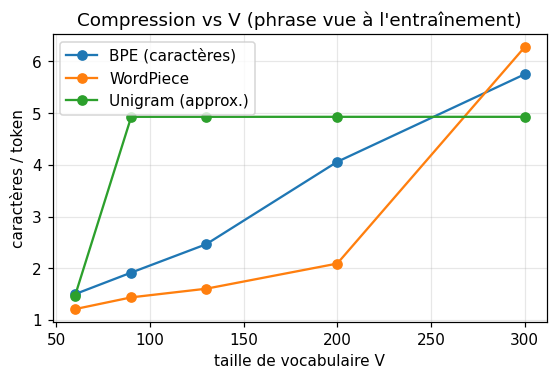

In [4]:
tailles = [60, 90, 130, 200, 300]
res = {c.nom: [] for c in (BPEChar, WordPiece, Unigram)}
for V_ in tailles:
    for c in (BPEChar, WordPiece, Unigram):
        m = c().entrainer(V_); res[c.nom].append(n_car / len(m.tokeniser("les chercheurs comparent les hypothèses. the model learns patterns.")) * 1.0)
plt.figure(figsize=(5.8, 3.4))
for k, v in res.items(): plt.plot(tailles, v, "o-", label=k)
plt.xlabel("taille de vocabulaire V"); plt.ylabel("caractères / token"); plt.title("Compression vs V (phrase vue à l'entraînement)"); plt.legend(); plt.show()

## Bilan
| Critère | BPE octets | BPE caractères | WordPiece | Unigram |
|---|---|---|---|---|
| `<unk>` possible | non | oui | oui | oui |
| Déterminisme de l'encodage | oui (règles ordonnées) | oui | oui (glouton) | non : plusieurs segmentations (régularisation) |
| Régularisation par échantillonnage | non (BPE-dropout possible) | — | — | **oui** [3] |

**Recommandation pour ce dépôt** : BPE **octets** + pré-tokenisation pour l'entraînement d'un LLM (aucun `<unk>`, rapide à encoder). Unigram si l'on veut échantillonner des segmentations.

**Limites** : corpus minuscule (les différences entre algorithmes sont dominées par la taille du corpus) ; Unigram est une approximation (pas d'EM complet, élagage par comptage d'usage) ; 1 seul corpus, pas de répétition. La qualité *aval* (perplexité d'un LM selon le tokenizer) n'est pas mesurée ici : elle dépend aussi de $V$ et doit être comparée en **bits par octet**, pas en perte par token.

## Références

1. **Sennrich, Haddow & Birch (2016)**. *Neural Machine Translation of Rare Words with Subword Units*. ACL. [lien](https://arxiv.org/abs/1508.07909)
2. **Wu et al. (2016)**. *Google's Neural Machine Translation System (WordPiece)*. arXiv. [lien](https://arxiv.org/abs/1609.08144)
3. **Kudo (2018)**. *Subword Regularization: Improving NMT Models with Multiple Subword Candidates (Unigram LM)*. ACL. [lien](https://arxiv.org/abs/1804.10959)
4. **Kudo & Richardson (2018)**. *SentencePiece: A simple and language independent subword tokenizer*. EMNLP (demo). [lien](https://arxiv.org/abs/1808.06226)
5. **Radford et al. (2019)**. *Language Models are Unsupervised Multitask Learners (GPT-2)*. OpenAI technical report. [lien](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)